In [2]:
import torch
import torch.nn as nn

class MLP(nn.Module):
    # 定义MLP类，继承nn.Module，PyTorch所有网络都要继承这个父类
    def __init__(self, input_size, hidden_size, output_size):
        """
        初始化多层感知机
        参数:
            input_size: 输入特征维度
            hidden_size: 隐藏层神经元数量
            output_size: 输出维度
        """
        super(MLP, self).__init__()
        # 调用父类nn.Module的构造函数，必须写，初始化网络底层模块

        # TODO: 定义全连接层和激活函数
        self.fc1 = nn.Linear(input_size, hidden_size)
        # 全连接层1：输入维度input_size → 输出hidden_size（隐藏层神经元）
        self.fc2 = nn.Linear(hidden_size, output_size)
        # 全连接层2：隐藏层维度 → 输出维度（二分类输出1个值）
        self.relu = nn.ReLU()
        # 实例化ReLU激活函数，用于隐藏层，引入非线性
        self.sigmoid = nn.Sigmoid()
        # 实例化Sigmoid激活函数，输出层，把数值压缩到0~1，代表概率

    def forward(self, x):
        """
        前向传播
        参数:
            x: 输入数据，形状为 (batch_size, input_size)
        返回:
            输出值，形状为 (batch_size, output_size)
        """
        # TODO: 补全前向传播过程
        x = self.relu(self.fc1(x))
        # 数据先送入fc1全连接层，再经过ReLU激活
        x = self.sigmoid(self.fc2(x))
        # 数据送入fc2全连接层，再经过Sigmoid得到0~1概率
        return x
        # 返回模型预测结果


In [3]:
def generate_moon_data(n_samples=1000, noise=0.15, test_size=0.2):
    """
    生成双月数据集并划分训练/测试集

    返回:
        X_train, X_test, y_train, y_test (均为 numpy 数组)
    """
    from sklearn.datasets import make_moons
    from sklearn.model_selection import train_test_split

    # TODO: 生成数据、标准化、划分训练/测试集
    X, y = make_moons(n_samples=n_samples, noise=noise, random_state=42)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=42)
    
    return X_train, X_test, y_train, y_test

In [4]:
# 生成数据，调用上面写好的函数，得到训练、测试集numpy数组
X_train, X_test, y_train, y_test = generate_moon_data()

# numpy数组 → torch浮点张量，pytorch计算必须用tensor
X_train_tensor = torch.from_numpy(X_train).float()
y_train_tensor = torch.from_numpy(y_train).float().unsqueeze(1)
# unsqueeze(1)：增加一维，把y从shape[800]变成[800,1]，匹配网络输出shape
X_test_tensor = torch.from_numpy(X_test).float()
y_test_tensor = torch.from_numpy(y_test).float().unsqueeze(1)

# TODO 实例化模型、损失、优化器
model = MLP(input_size=2, hidden_size=16, output_size=1)
# 实例化MLP：输入2维（双月每个样本x1,x2两个特征），隐藏层16神经元，输出1维
criterion = nn.BCELoss()
# BCELoss：二分类交叉熵损失函数，配合sigmoid输出做二分类
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
# Adam优化器，更新模型权重；lr学习率0.01

# 列表用来保存每一轮的损失、准确率，后续画图
train_loss_list = []
test_loss_list = []
train_acc_list = []
test_acc_list = []
epochs = 300  # 总训练轮数，全部数据循环训练300次

for epoch in range(epochs):
    # 循环，每一轮epoch代表完整过一遍全部训练集
    # TODO 训练前向、反向、更新
    model.train()
    # 设置模型为训练模式：启用Dropout等训练专属功能（本实验无dropout，规范写法）
    optimizer.zero_grad()
    # 梯度清零
    y_pred = model(X_train_tensor)
    # 前向传播：把训练数据送入模型，得到预测概率
    loss_train = criterion(y_pred, y_train_tensor)
    # 计算训练损失：对比预测值和真实标签
    loss_train.backward()
    # 反向传播，自动求导，计算每个参数的梯度
    optimizer.step()
    # 优化器根据梯度更新权重参数

    pred_train = (y_pred > 0.5).float()
    # 概率>0.5判定为类别1，否则0；转成浮点tensor
    acc_train = (pred_train == y_train_tensor).float().mean()
    # 预测等于真实标签为1，不等为0；求平均值得到训练集准确率

    # TODO 测试集评估
    model.eval()
    # 设置模型评估模式，关闭dropout、bn等训练独有操作
    with torch.no_grad():
        # 关闭梯度计算，测试阶段不需要计算梯度，节省内存加速
        y_pred_test = model(X_test_tensor)
        # 测试集前向传播，得到预测
        loss_test = criterion(y_pred_test, y_test_tensor)
        # 计算测试集损失
        pred_test = (y_pred_test > 0.5).float()
        # 测试集预测类别
        acc_test = (pred_test == y_test_tensor).float().mean()
        # 测试集准确率

    # 把本轮结果存入列表，用于后续绘图
    train_loss_list.append(loss_train.item())
    test_loss_list.append(loss_test.item())
    train_acc_list.append(acc_train.item())
    test_acc_list.append(acc_test.item())


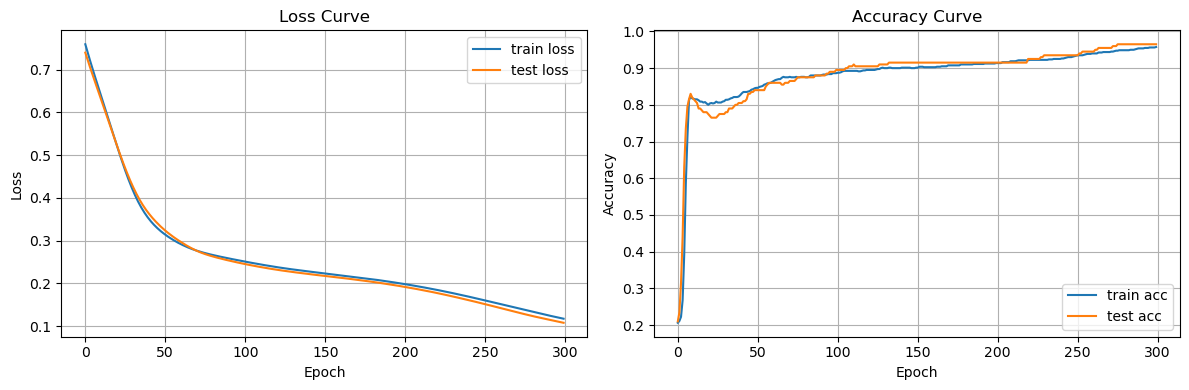

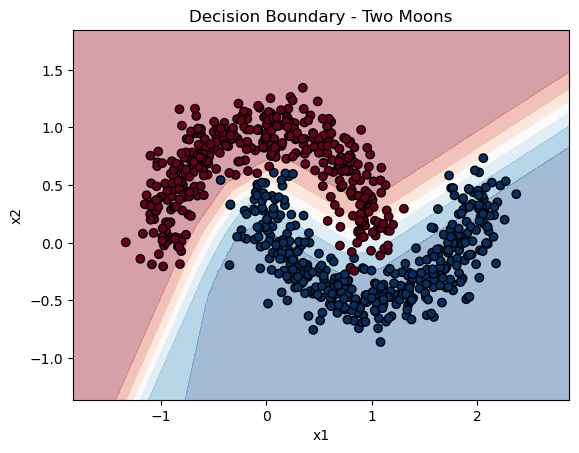

In [6]:
import matplotlib.pyplot as plt
import numpy as np

# TODO 绘制损失&准确率曲线
plt.figure(figsize=(12,4))
# 创建画布，大小宽12，高4英寸
plt.subplot(1,2,1)
# 划分画布：1行2个子图，当前画第1个
plt.plot(train_loss_list, label="train loss")
# 绘制训练损失曲线
plt.plot(test_loss_list, label="test loss")
# 绘制测试损失曲线
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss Curve")
plt.legend() # 显示图例
plt.grid(True) # 显示网格线

plt.subplot(1,2,2) # 1行2列，第2张子图
plt.plot(train_acc_list, label="train acc")
plt.plot(test_acc_list, label="test acc")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy Curve")
plt.legend()
plt.grid(True)
plt.tight_layout() # 自动调整子图间距，防止文字重叠
plt.show() # 展示图片

# TODO 绘制决策边界
def plot_decision_boundary(model, X, y):
    # 定义绘制决策边界的函数
    x_min, x_max = X[:,0].min()-0.5, X[:,0].max()+0.5
    # 获取特征x1的最小、最大值，向外扩展一点边界
    y_min, y_max = X[:,1].min()-0.5, X[:,1].max()+0.5
    # 获取特征x2的最小、最大值
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100),
                         np.linspace(y_min, y_max, 100))
    # meshgrid生成网格坐标点，100×100个点，铺满整个坐标平面
    grid = np.c_[xx.ravel(), yy.ravel()]
    # 把网格坐标展平，拼接成N行2列的特征数组，送入模型预测
    grid_tensor = torch.from_numpy(grid).float() # numpy转tensor
    model.eval()
    with torch.no_grad():
        pred = model(grid_tensor) # 对所有网格点做预测
    pred = pred.reshape(xx.shape).numpy() # 预测结果还原成网格形状，转回numpy
    plt.contourf(xx, yy, pred, alpha=0.4, cmap="RdBu")
    # 填充等高线，画出分类区域，alpha透明度0.4，红蓝配色
    plt.scatter(X[:,0], X[:,1], c=y, cmap="RdBu", edgecolors="k")
    # 绘制原始样本点，按标签上色，黑色描边
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title("Decision Boundary - Two Moons")

plt.figure() #新建画布
plot_decision_boundary(model, X_train, y_train) #调用函数绘图
plt.show()
